In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA
from scipy import stats
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = sns.load_dataset('iris')
print(df.info())
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [3]:
x_cols = ['sepal_length', 'sepal_width']
y_cols = ['petal_length', 'petal_width']
X_raw = df[x_cols].to_numpy()
Y_raw = df[y_cols].to_numpy()


X = StandardScaler().fit_transform(X_raw)
Y = StandardScaler().fit_transform(Y_raw)

n_components = min(X.shape[1], Y.shape[1])
cca = CCA(n_components=n_components).fit(X, Y)
X_c, Y_c = cca.transform(X, Y)
canon_corrs = [np.corrcoef(X_c[:, i], Y_c[:, i])[0, 1] for i in range(n_components)]
print('Точечные оценки канонических корреляций:', np.round(canon_corrs, 3))


Точечные оценки канонических корреляций: [0.941 0.124]


In [5]:
n = X.shape[0]
rng = np.random.RandomState(1)
n_boot = 1000
boot_corrs = []

for i in range(n_boot):
    idx = rng.choice(n, size=n, replace=True)
    Xb, Yb = X[idx], Y[idx]
    try:
        cca_b = CCA(n_components=n_components).fit(Xb, Yb)
        Xb_c, Yb_c = cca_b.transform(Xb, Yb)
        r_b = np.corrcoef(Xb_c[:, 0], Yb_c[:, 0])[0, 1]
        if np.isfinite(r_b):
            boot_corrs.append(r_b)
    except Exception:
        continue

boot_corrs = np.array(boot_corrs)
print('Успешных бутстреп-повторов:', len(boot_corrs), 'из', n_boot)
print('Среднее бутстреп-оценки:', boot_corrs.mean().round(3))
print('Стандартная ошибка (бутстреп):', boot_corrs.std(ddof=1).round(3))


Успешных бутстреп-повторов: 1000 из 1000
Среднее бутстреп-оценки: 0.942
Стандартная ошибка (бутстреп): 0.008


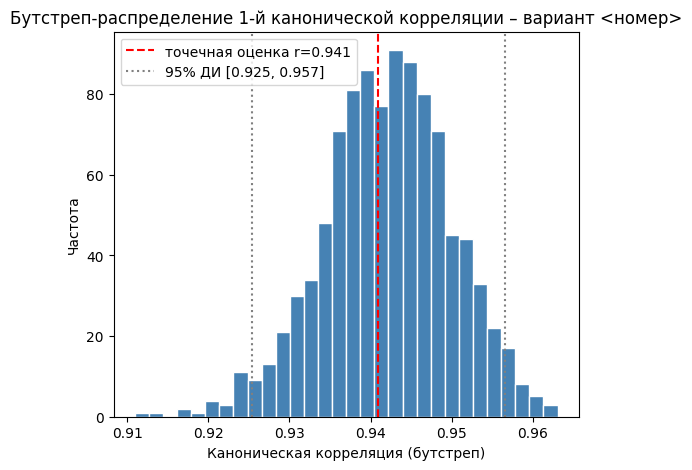

In [6]:
ci_low, ci_high = np.percentile(boot_corrs, [2.5, 97.5])

plt.figure(figsize=(6, 5))
plt.hist(boot_corrs, bins=30, color='steelblue', edgecolor='white')
plt.axvline(canon_corrs[0], color='red', linestyle='--', label=f'точечная оценка r={canon_corrs[0]:.3f}')
plt.axvline(ci_low, color='gray', linestyle=':', label=f'95% ДИ [{ci_low:.3f}, {ci_high:.3f}]')
plt.axvline(ci_high, color='gray', linestyle=':')
plt.xlabel('Каноническая корреляция (бутстреп)')
plt.ylabel('Частота')
plt.title('Бутстреп-распределение 1-й канонической корреляции – вариант <номер>')
plt.legend()
plt.savefig('bootstrap_hist.png', dpi=150, bbox_inches='tight')
plt.show()


In [7]:
def wilks_test(corrs, n, p_vars, q_vars):
    lam = np.prod([1 - r**2 for r in corrs])
    df = p_vars * q_vars
    chi2_stat = -(n - 1 - (p_vars + q_vars + 1) / 2) * np.log(lam)
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)
    return lam, chi2_stat, df, p_value

lam, chi2_stat, df, p_value = wilks_test(canon_corrs, X.shape[0], X.shape[1], Y.shape[1])
print(f"Wilks' Lambda = {lam:.4f}")
print(f'chi2 = {chi2_stat:.3f}, df = {df}, p-value = {p_value:.4f}')

alpha = 0.05
if p_value < alpha:
    print('H0 отклонена: связь между блоками X и Y статистически значима')
else:
    print('H0 не отклонена: значимой связи между блоками не обнаружено')


Wilks' Lambda = 0.1128
chi2 = 319.661, df = 4, p-value = 0.0000
H0 отклонена: связь между блоками X и Y статистически значима


In [10]:
summary = pd.DataFrame({
    'Показатель': ['Точечная оценка r1 (ЛР3)', 'Бутстреп: среднее', 'Бутстреп: 95% ДИ',
                   "Wilks' Lambda", 'chi2', 'p-value (Уилкс)'],
    'Значение': [round(canon_corrs[0], 3), round(boot_corrs.mean(), 3),
                 f'[{ci_low:.3f}, {ci_high:.3f}]', round(lam, 4),
                 round(chi2_stat, 3), round(p_value, 4)]
})
print(summary.to_string(index=False))


              Показатель       Значение
Точечная оценка r1 (ЛР3)          0.941
       Бутстреп: среднее          0.942
        Бутстреп: 95% ДИ [0.925, 0.957]
           Wilks' Lambda         0.1128
                    chi2        319.661
         p-value (Уилкс)            0.0
